# SL t-SNE Report

Short supervised-learning t-SNE report on `data/processed_fullyonehot/fullyonehot.csv`.

It compares:
- **SL-RF t-SNE**: Random Forest proximity distance from shared leaf assignments.
- **SL-CatBoost t-SNE**: CatBoost weighted leaf/path distance using oblivious-tree path similarity, leaf IDF, and tree decay.

## 1. Imports and Data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from catboost import CatBoostClassifier
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    pairwise_distances,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

OUT_DIR = PROJECT / "visualization" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

try:
    import hdbscan
except Exception:
    hdbscan = None


In [2]:
DATA_PATH = PROJECT / "data" / "processed_fullyonehot" / "fullyonehot.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_map = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate",
}
target_order = ["Dropout", "Enrolled", "Graduate"]

target_col = "Target"
df[target_col] = df[target_col].astype(int)
df["Target Label"] = df[target_col].map(target_map)
feature_cols = [c for c in df.columns if c not in [target_col, "Target Label"]]
target_label_all = df["Target Label"].to_numpy()

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df[target_col])

train_idx, holdout_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_all,
    shuffle=True,
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_all[holdout_idx],
    shuffle=True,
)

X_all = df[feature_cols].astype("float32")
X_train = X_all.iloc[train_idx]
X_val = X_all.iloc[val_idx]
X_test = X_all.iloc[test_idx]
y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

split_all = np.empty(len(df), dtype=object)
split_all[train_idx] = "train"
split_all[val_idx] = "val"
split_all[test_idx] = "test"

palette = {"Dropout": "#d55e00", "Enrolled": "#0072b2", "Graduate": "#009e73"}
zone_palette = {
    "safe_abs": "#009e73",
    "danger_abs": "#d55e00",
    "atypical_danger": "#cc79a7",
    "swing_ambiguous": "#0072b2",
    "other_pure": "#999999",
}

print("Data path:", DATA_PATH)
print("Full one-hot data:", df.shape)
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)
display(pd.Series(target_label_all).value_counts().to_frame("count"))


Data path: /Users/husrcf/Code/Machine-Learning-Project/data/processed_fullyonehot/fullyonehot.csv
Full one-hot data: (4424, 263)
Train / Val / Test: (3096, 261) (664, 261) (664, 261)


,count
Graduate,2209
Dropout,1421
Enrolled,794


## 2. Shared Helpers

In [3]:
def evaluate_classifier(name, model, X_test, y_test):
    pred = model.predict(X_test)
    if pred.ndim > 1:
        pred = pred.reshape(-1)
    pred = pred.astype(int)
    proba = model.predict_proba(X_test)
    row = {
        "Model": name,
        "Test accuracy": accuracy_score(y_test, pred),
        "Test macro-F1": f1_score(y_test, pred, average="macro"),
        "Test AUC OVR": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
    }
    print(name)
    class_names = [target_map[int(cls)] for cls in label_encoder.classes_]
    print(classification_report(y_test, pred, target_names=class_names))
    return row


def run_tsne(distance, n_components=2, random_state=RANDOM_STATE):
    tsne = TSNE(
        n_components=n_components,
        perplexity=30,
        learning_rate="auto",
        init="random",
        metric="precomputed",
        random_state=random_state,
    )
    return tsne.fit_transform(distance)


def plot_embedding(
    embedding,
    title,
    out_name,
    color_values=None,
    color_name="Target",
    color_order=None,
    color_palette=None,
):
    if color_values is None:
        color_values = target_label_all
    if color_order is None and color_name == "Target":
        color_order = target_order
    if color_palette is None and color_name == "Target":
        color_palette = palette

    columns = ["TSNE1", "TSNE2"] if embedding.shape[1] == 2 else ["TSNE1", "TSNE2", "TSNE3"]
    plot_df = pd.DataFrame(embedding, columns=columns)
    plot_df[color_name] = color_values
    plot_df["Split"] = split_all

    if embedding.shape[1] == 2:
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.scatterplot(
            data=plot_df,
            x="TSNE1",
            y="TSNE2",
            hue=color_name,
            hue_order=color_order,
            palette=color_palette,
            s=18,
            alpha=0.78,
            linewidth=0,
            ax=ax,
        )
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
    else:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")
        if color_order is None:
            color_order = pd.Series(color_values).dropna().astype(str).sort_values().unique().tolist()
        for value in color_order:
            sub = plot_df[plot_df[color_name] == value]
            color = color_palette.get(value) if isinstance(color_palette, dict) else None
            ax.scatter(
                sub["TSNE1"],
                sub["TSNE2"],
                sub["TSNE3"],
                s=12,
                alpha=0.78,
                color=color,
                label=value,
            )
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
        ax.set_zlabel("t-SNE 3")

    ax.set_title(title)
    ax.legend(title=color_name, frameon=True)
    plt.tight_layout()
    fig.savefig(OUT_DIR / out_name, bbox_inches="tight")
    plt.show()


def export_3d_embedding_html(
    embedding,
    title,
    out_name,
    color_values=None,
    color_name="Target",
    color_order=None,
    color_palette=None,
    cluster_labels=None,
    zones=None,
):
    if embedding.shape[1] != 3:
        raise ValueError("Interactive HTML export expects a 3D embedding.")

    if color_values is None:
        color_values = target_label_all
    if color_order is None and color_name == "Target":
        color_order = target_order
    if color_palette is None and color_name == "Target":
        color_palette = palette

    plot_df = pd.DataFrame(embedding, columns=["TSNE1", "TSNE2", "TSNE3"])
    plot_df["SampleIndex"] = np.arange(len(plot_df))
    plot_df["Target"] = target_label_all
    plot_df["Split"] = split_all
    plot_df[color_name] = color_values

    if cluster_labels is not None:
        plot_df["Cluster"] = cluster_labels.astype(str)
    if zones is not None:
        plot_df["Zone"] = zones

    hover_data = ["SampleIndex", "Target", "Split"]
    if "Cluster" in plot_df.columns:
        hover_data.append("Cluster")
    if "Zone" in plot_df.columns and color_name != "Zone":
        hover_data.append("Zone")

    fig = px.scatter_3d(
        plot_df,
        x="TSNE1",
        y="TSNE2",
        z="TSNE3",
        color=color_name,
        symbol="Split",
        color_discrete_map=color_palette,
        category_orders={color_name: color_order} if color_order is not None else None,
        hover_data=hover_data,
        title=title,
    )
    fig.update_traces(marker={"size": 3, "opacity": 0.78})
    fig.update_layout(
        template="plotly_white",
        width=1100,
        height=820,
        legend_title_text=color_name,
        margin={"l": 0, "r": 0, "t": 55, "b": 0},
        scene={
            "xaxis_title": "t-SNE 1",
            "yaxis_title": "t-SNE 2",
            "zaxis_title": "t-SNE 3",
        },
    )
    fig.write_html(OUT_DIR / out_name, include_plotlyjs=True, full_html=True)
    print("Interactive HTML:", OUT_DIR / out_name)


def run_cluster_on_distance(distance, method="agglomerative", n_clusters=8):
    if method == "hdbscan":
        if hdbscan is None:
            raise RuntimeError("hdbscan is not installed; use method='agglomerative'.")
        clusterer = hdbscan.HDBSCAN(
            metric="precomputed",
            min_cluster_size=25,
            min_samples=None,
            cluster_selection_method="eom",
        )
        return clusterer.fit_predict(distance)

    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        metric="precomputed",
        linkage="average",
    )
    return model.fit_predict(distance)


def zone_summary_from_clusters(cluster_labels, pure_threshold=0.95, atypical_threshold=0.70):
    rows = []
    target_values = pd.Series(target_label_all)
    for cid in np.unique(cluster_labels):
        idx = cluster_labels == cid
        size = int(idx.sum())
        if size == 0:
            continue

        count = target_values[idx].value_counts()
        dominant = count.idxmax()
        dominant_ratio = float(count.max() / size)

        if cid == -1:
            zone = "swing_ambiguous"
        elif dominant_ratio >= pure_threshold:
            if dominant == "Graduate":
                zone = "safe_abs"
            elif dominant == "Dropout":
                zone = "danger_abs"
            else:
                zone = "other_pure"
        elif dominant == "Dropout" and dominant_ratio >= atypical_threshold:
            zone = "atypical_danger"
        else:
            zone = "swing_ambiguous"

        rows.append(
            {
                "cluster": int(cid),
                "size": size,
                "dominant": dominant,
                "dominant_ratio": dominant_ratio,
                "zone": zone,
                **{name: int(count.get(name, 0)) for name in target_order},
            }
        )
    return pd.DataFrame(rows).sort_values(["zone", "cluster"]).reset_index(drop=True)


def knn_label_agreement(distance, labels, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="precomputed")
    nn.fit(distance)
    indices = nn.kneighbors(return_distance=False)[:, 1:]
    return (labels[indices] == labels[:, None]).mean()


def distance_quality(name, distance, embedding):
    return {
        "Method": name,
        "Distance silhouette": silhouette_score(distance, y_all, metric="precomputed"),
        "Embedding silhouette": silhouette_score(embedding, y_all),
        "Distance KNN label agreement@15": knn_label_agreement(distance, y_all, k=15),
    }


## 3. SL-RF Proximity t-SNE

SL-RF
              precision    recall  f1-score   support

     Dropout       0.84      0.71      0.77       214
    Enrolled       0.49      0.67      0.57       119
    Graduate       0.88      0.86      0.87       331

    accuracy                           0.78       664
   macro avg       0.74      0.75      0.74       664
weighted avg       0.80      0.78      0.78       664



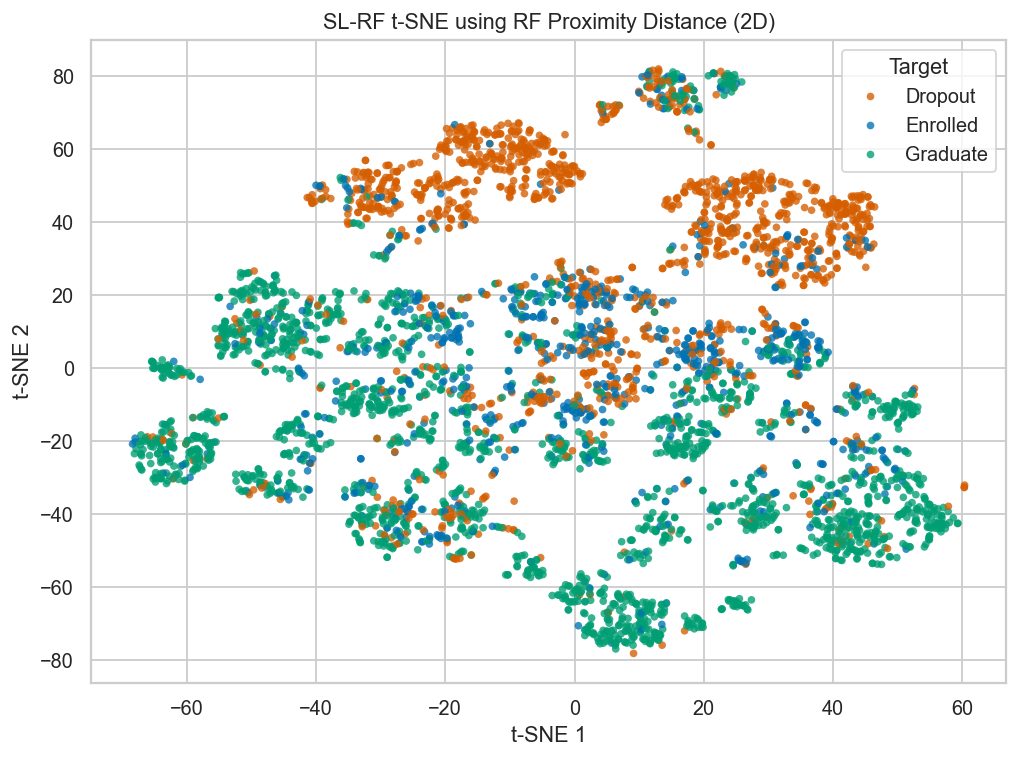

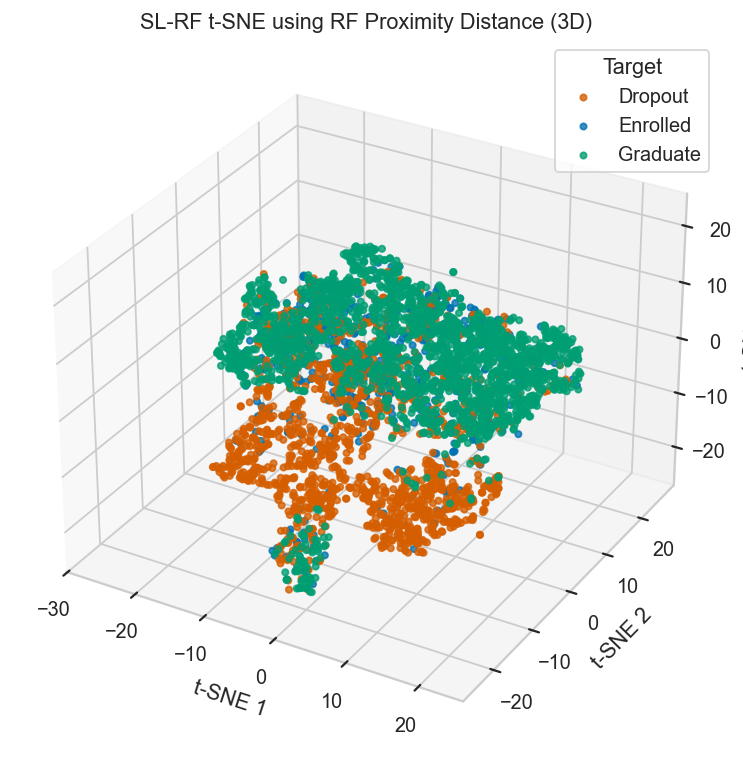

Interactive HTML: /Users/husrcf/Code/Machine-Learning-Project/visualization/outputs/sl_rf_proximity_tsne_3d.html


In [4]:
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=8,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_cv_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
rf.fit(X_train, y_train)

rf_metric = evaluate_classifier("SL-RF", rf, X_test, y_test)
rf_metric["CV macro-F1 mean"] = rf_cv_f1.mean()
rf_metric["CV macro-F1 std"] = rf_cv_f1.std()

rf_leaves = rf.apply(X_all)
rf_distance = pairwise_distances(rf_leaves, metric="hamming").astype("float32")
np.fill_diagonal(rf_distance, 0.0)

rf_embedding = run_tsne(rf_distance, n_components=2)
plot_embedding(rf_embedding, "SL-RF t-SNE using RF Proximity Distance (2D)", "sl_rf_proximity_tsne.png")

rf_embedding_3d = run_tsne(rf_distance, n_components=3)
plot_embedding(rf_embedding_3d, "SL-RF t-SNE using RF Proximity Distance (3D)", "sl_rf_proximity_tsne_3d.png")

export_3d_embedding_html(
    rf_embedding_3d,
    "SL-RF t-SNE using RF Proximity Distance (Interactive 3D)",
    "sl_rf_proximity_tsne_3d.html",
)



## 4. SL-CatBoost Weighted Leaf t-SNE

In [5]:
catboost = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    auto_class_weights="Balanced",
    depth=6,
    iterations=500,
    l2_leaf_reg=9,
    learning_rate=0.05,
    random_strength=1.0,
    random_seed=42,
    verbose=0,
)

catboost.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=0)
cb_metric = evaluate_classifier("SL-CatBoost", catboost, X_test, y_test)

cb_leaves = catboost.calc_leaf_indexes(X_all)
print("CatBoost leaf matrix:", cb_leaves.shape)

SL-CatBoost
              precision    recall  f1-score   support

     Dropout       0.87      0.75      0.81       214
    Enrolled       0.50      0.71      0.59       119
    Graduate       0.89      0.83      0.86       331

    accuracy                           0.78       664
   macro avg       0.75      0.76      0.75       664
weighted avg       0.81      0.78      0.79       664

CatBoost leaf matrix: (4424, 456)


### 4.1 Weighted leaf/path distance

CatBoost weighted distance: (4424, 4424) float32
Distance range: 0.0 0.6478706002235413


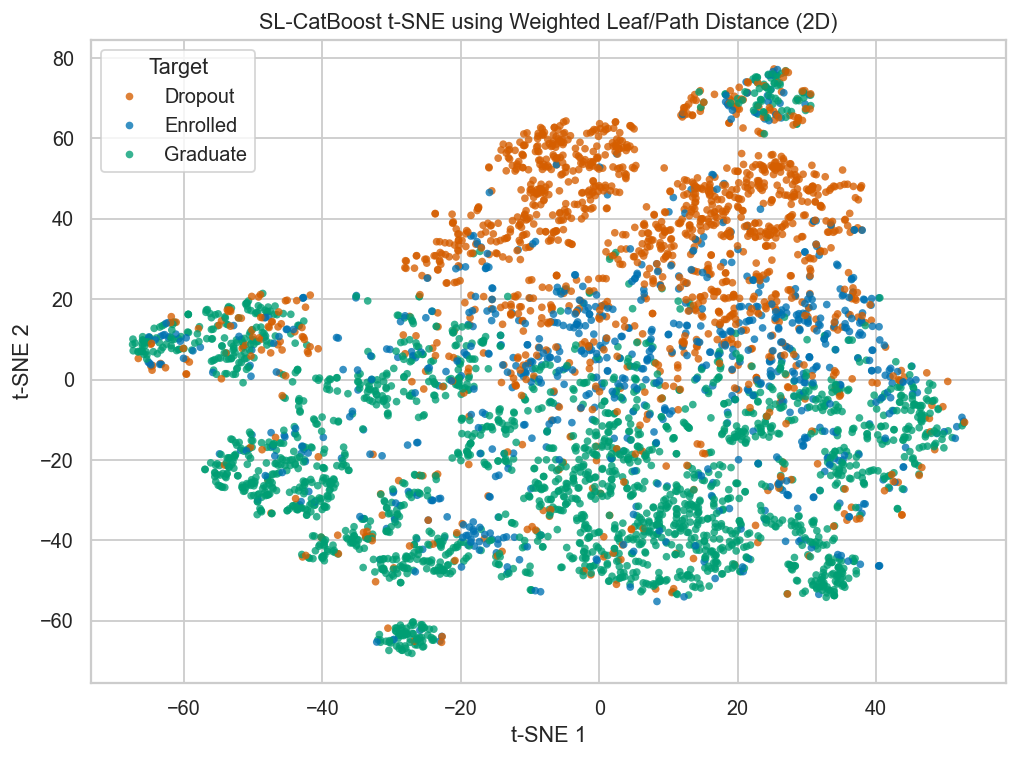

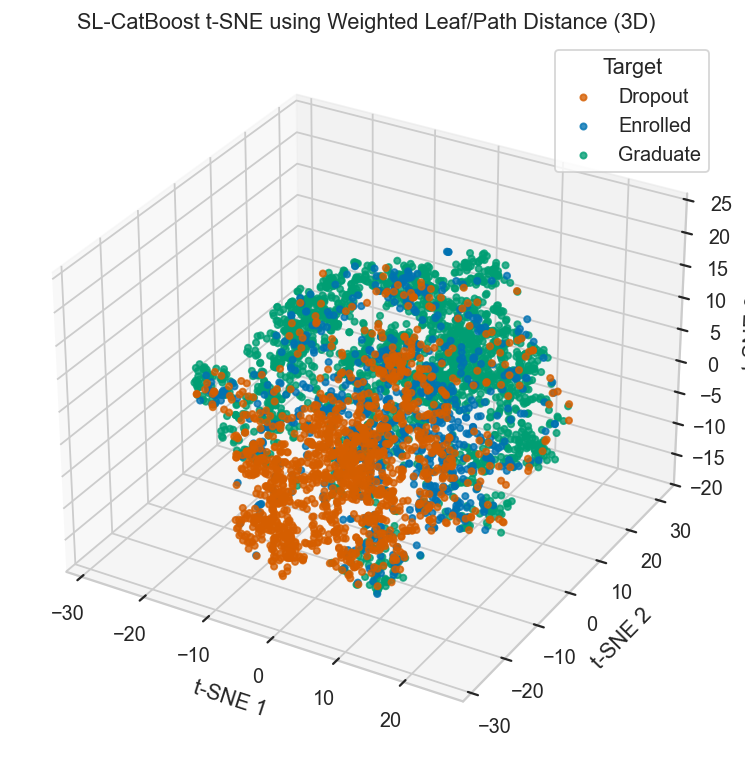

Interactive HTML: /Users/husrcf/Code/Machine-Learning-Project/visualization/outputs/sl_catboost_weighted_leaf_tsne_3d.html


In [6]:
def catboost_weighted_leaf_distance(leaves, depth=6, gamma=0.003, eps=1e-6):
    leaves = leaves.astype(np.uint32)
    n_samples, n_trees = leaves.shape
    path_similarity_sum = np.zeros((n_samples, n_samples), dtype=np.float32)
    weight_sum = np.zeros((n_samples, n_samples), dtype=np.float32)
    tree_weights = np.exp(-gamma * np.arange(n_trees, dtype=np.float32))
    popcount_lookup = np.array([int(value).bit_count() for value in range(2**depth)], dtype=np.float32)

    for t in range(n_trees):
        leaf_t = leaves[:, t]
        xor = np.bitwise_xor(leaf_t[:, None], leaf_t[None, :])
        hamming = popcount_lookup[xor]
        path_similarity = 1.0 - hamming / depth

        _, inverse, counts = np.unique(leaf_t, return_inverse=True, return_counts=True)
        idf = np.log(n_samples / (counts[inverse].astype(np.float32) + eps))
        pair_weight = (idf[:, None] + idf[None, :]) * 0.5
        weighted = tree_weights[t] * pair_weight

        path_similarity_sum += weighted * path_similarity
        weight_sum += weighted

    similarity = path_similarity_sum / np.maximum(weight_sum, eps)
    similarity = np.clip(similarity, 0.0, 1.0)
    distance = (1.0 - similarity).astype("float32")
    np.fill_diagonal(distance, 0.0)
    return distance

cb_distance = catboost_weighted_leaf_distance(cb_leaves, depth=6, gamma=0.003)
print("CatBoost weighted distance:", cb_distance.shape, cb_distance.dtype)
print("Distance range:", float(cb_distance.min()), float(cb_distance.max()))

cb_embedding = run_tsne(cb_distance, n_components=2)
plot_embedding(
    cb_embedding,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (2D)",
    "sl_catboost_weighted_leaf_tsne.png",
)

cb_embedding_3d = run_tsne(cb_distance, n_components=3)
plot_embedding(
    cb_embedding_3d,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (3D)",
    "sl_catboost_weighted_leaf_tsne_3d.png",
)

export_3d_embedding_html(
    cb_embedding_3d,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (Interactive 3D)",
    "sl_catboost_weighted_leaf_tsne_3d.html",
)



## 5. SL-CatBoost Leaf Co-occurrence Proximity Matrix

This section uses the standard CatBoost proximity matrix: two samples are more similar when they land in the same leaf across more CatBoost trees. The distance is `1 - proximity`, and clustering is run directly on this precomputed distance matrix.


CatBoost proximity distance: (4424, 4424) float32
Distance range: 0.0 0.984649121761322


CatBoost proximity clustering summary:


,cluster,size,dominant,dominant_ratio,zone,Dropout,Enrolled,Graduate
0,0,28,Dropout,0.750000,atypical_danger,21,3,4
1,1,21,Dropout,0.904762,atypical_danger,19,2,0
2,2,1390,Dropout,0.721583,atypical_danger,1003,261,126
3,3,9,Dropout,0.777778,atypical_danger,7,1,1
4,7,14,Dropout,0.714286,atypical_danger,10,1,3
5,4,275,Graduate,0.643636,swing_ambiguous,63,35,177
6,5,2684,Graduate,0.706781,swing_ambiguous,298,489,1897
7,6,3,Enrolled,0.666667,swing_ambiguous,0,2,1


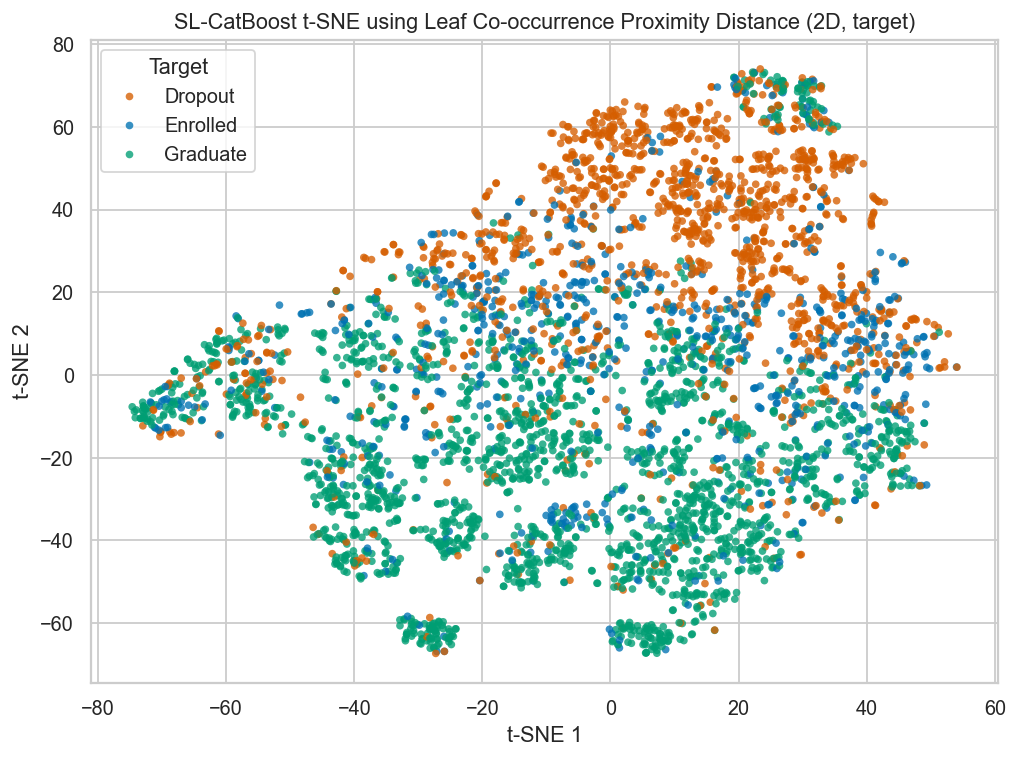

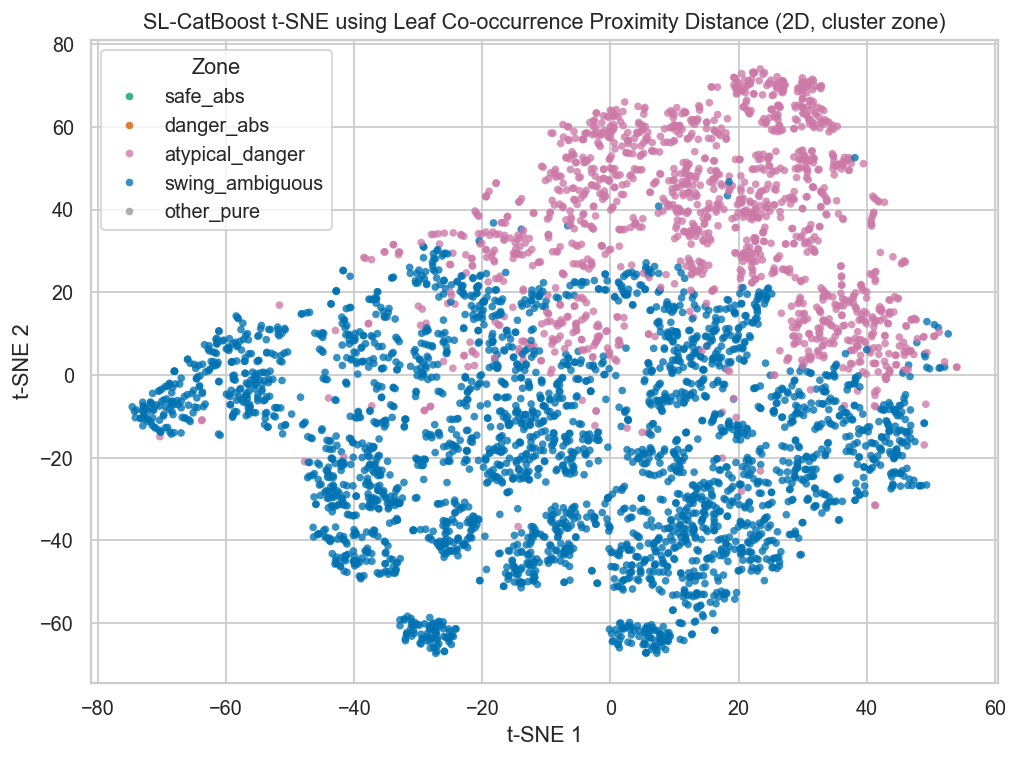

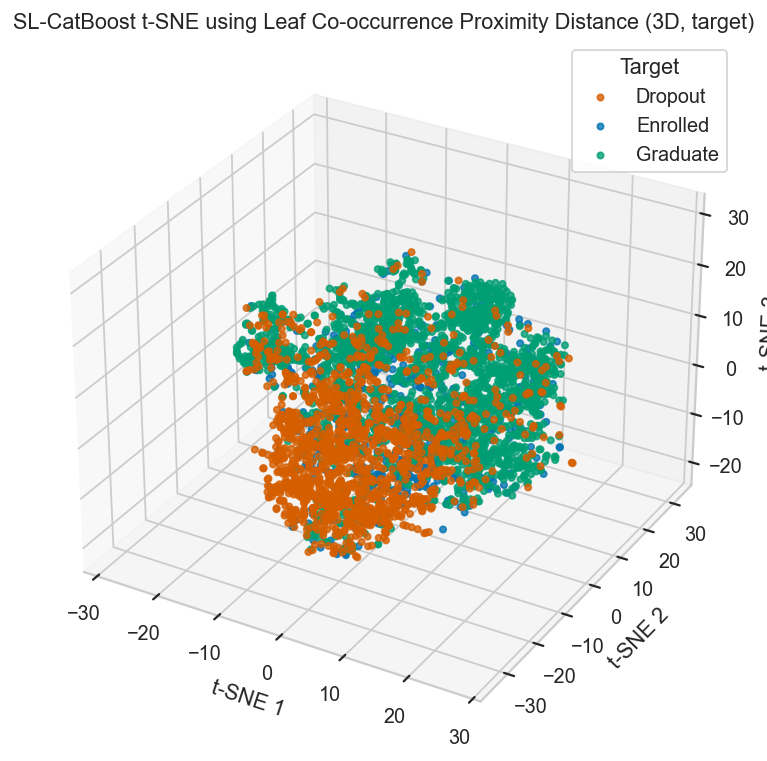

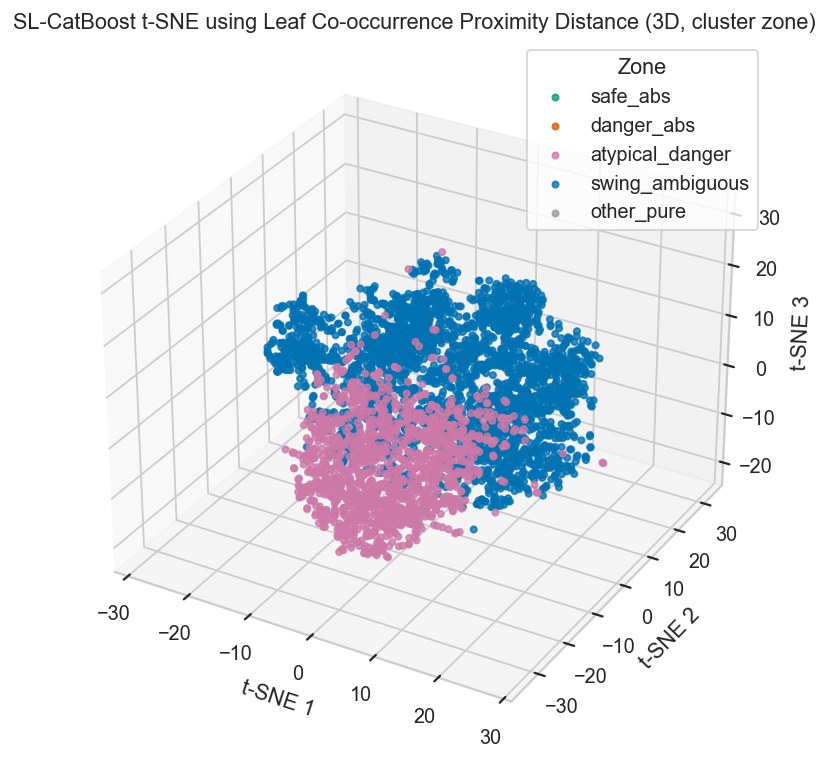

Interactive HTML: /Users/husrcf/Code/Machine-Learning-Project/visualization/outputs/sl_catboost_leaf_proximity_tsne_3d.html
Interactive HTML: /Users/husrcf/Code/Machine-Learning-Project/visualization/outputs/sl_catboost_leaf_proximity_cluster_zone_tsne_3d.html


In [7]:
def catboost_leaf_cooccurrence_distance(leaves):
    leaves = leaves.astype(np.int32)
    n_samples, n_trees = leaves.shape
    proximity = np.zeros((n_samples, n_samples), dtype=np.float32)

    for t in range(n_trees):
        leaf_t = leaves[:, t]
        proximity += leaf_t[:, None] == leaf_t[None, :]

    proximity /= np.float32(n_trees)
    distance = (1.0 - proximity).astype("float32")
    np.fill_diagonal(distance, 0.0)
    return distance

cb_proximity_distance = catboost_leaf_cooccurrence_distance(cb_leaves)
print("CatBoost proximity distance:", cb_proximity_distance.shape, cb_proximity_distance.dtype)
print("Distance range:", float(cb_proximity_distance.min()), float(cb_proximity_distance.max()))

cb_proximity_cluster_labels = run_cluster_on_distance(
    cb_proximity_distance,
    method="agglomerative",
    n_clusters=8,
)
cb_proximity_cluster_summary = zone_summary_from_clusters(cb_proximity_cluster_labels)
print("CatBoost proximity clustering summary:")
display(cb_proximity_cluster_summary)

cb_proximity_cluster_zone_map = cb_proximity_cluster_summary.set_index("cluster")["zone"]
cb_proximity_cluster_zones = pd.Series(cb_proximity_cluster_labels).map(cb_proximity_cluster_zone_map).to_numpy()

cb_proximity_embedding = run_tsne(cb_proximity_distance, n_components=2)
plot_embedding(
    cb_proximity_embedding,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (2D, target)",
    "sl_catboost_leaf_proximity_tsne.png",
)
plot_embedding(
    cb_proximity_embedding,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (2D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne.png",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
)

cb_proximity_embedding_3d = run_tsne(cb_proximity_distance, n_components=3)
plot_embedding(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (3D, target)",
    "sl_catboost_leaf_proximity_tsne_3d.png",
)
plot_embedding(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (3D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne_3d.png",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
)

export_3d_embedding_html(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (Interactive 3D, target)",
    "sl_catboost_leaf_proximity_tsne_3d.html",
)
export_3d_embedding_html(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (Interactive 3D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne_3d.html",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
    cluster_labels=cb_proximity_cluster_labels,
    zones=cb_proximity_cluster_zones,
)



## 6. Compact Comparison


In [8]:
classifier_metrics = pd.DataFrame([rf_metric, cb_metric])
display(classifier_metrics.round(4))

quality = pd.DataFrame(
    [
        distance_quality("SL-RF proximity", rf_distance, rf_embedding),
        distance_quality("SL-CatBoost weighted leaf", cb_distance, cb_embedding),
        distance_quality("SL-CatBoost leaf co-occurrence proximity", cb_proximity_distance, cb_proximity_embedding),
    ]
)
quality["Random same-label baseline"] = pd.Series(y_all).value_counts(normalize=True).pow(2).sum()
display(quality.round(4))


,Model,Test accuracy,Test macro-F1,Test AUC OVR,CV macro-F1 mean,CV macro-F1 std
0,SL-RF,0.7756,0.7354,0.9030,0.6983,0.0182
1,SL-CatBoost,0.7846,0.7505,0.9109,NaN,NaN


,Method,Distance silhouette,Embedding silhouette,Distance KNN label agreement@15,Random same-label baseline
0,SL-RF proximity,0.0291,0.0303,0.6931,0.3847
1,SL-CatBoost weighted leaf,0.0641,0.0756,0.6849,0.3847
2,SL-CatBoost leaf co-occurrence proximity,0.0348,0.0783,0.6705,0.3847


## 7. Brief Conclusion

The original SL-RF and SL-CatBoost weighted leaf/path t-SNE analyses are kept, with 3D t-SNE views added after the original 2D graphs.
The added CatBoost leaf co-occurrence proximity branch uses same-leaf frequency across trees as the distance basis, clusters directly on that distance matrix, then visualizes the same distance matrix with 2D and 3D t-SNE.
